# Modelos de clasificación de texto y búsqueda de hiperparámetros

En este capítulo describimos los ocho modelos, el espacio de búsqueda de cada uno y lo que la búsqueda revela sobre la sensibilidad a los hiperparámetros. Todos los modelos ligeros reciben el mismo presupuesto: 30 *trials* de Optuna con TPE y poda por mediana {cite:p}`akiba2019optuna,bergstra2011tpe`, entrenando con entrenamiento y midiendo F1 macro en validación. Los resultados los generan los trabajos `nlp_hpo_*`, `nlp_nested_*` y `bert_lrgrid` de la cola.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from project.analysis_nlp import boundary_hits
from project.book_utils import CAT, ci, exists, need, style

style()
pd.set_option("display.precision", 3)
S = need("analysis/nlp_stats/stats.pkl")
L = S["labels"]

## Inventario

| Modelo | Implementación | Representación | Hiperparámetros buscados |
|---|---|---|---|
| Clase mayoritaria | Propia | — | — |
| TF-IDF + regresión logística | scikit-learn | TF-IDF (1–2 gramas) | C, n-gramas, frecuencia mínima, TF sublineal, tamaño del vocabulario, peso de clases |
| NB-SVM {cite:p}`wang2012nbsvm` | Propia sobre scikit-learn: 24 regresiones logísticas uno contra resto sobre rasgos binarios escalados por la razón de log-conteos | TF-IDF binario | C, α (suavizado), n-gramas, frecuencia mínima, vocabulario |
| TF-IDF + XGBoost {cite:p}`chen2016xgboost` | xgboost, 600 árboles con parada temprana (30 rondas) en validación | TF-IDF (1-gramas) | profundidad, tasa, submuestreo de filas y columnas, peso mínimo de hijo, vocabulario |
| FastText supervisado {cite:p}`joulin2017bag` | fasttext | n-gramas de palabra y de carácter | tasa, épocas, n-gramas de palabra, dimensión, n-gramas de carácter sí/no |
| **CNN-1D** {cite:p}`kim2014cnn` | **Propia en Keras**: filtros de ancho 2, 3, 4 y 5 en paralelo, *max-pooling* global con máscara de relleno | *embeddings* Word2Vec *skip-gram* (entrenamiento) | filtros, *dropout*, tasa, lote, longitud, épocas máximas, dimensión |
| **Word2Vec + BiLSTM** {cite:p}`hochreiter1997lstm` | **Propia en Keras**: 1 o 2 capas bidireccionales, *pooling* por último estado, máximo o atención aditiva {cite:p}`bahdanau2015attention`, máscara de relleno | *embeddings* Word2Vec *skip-gram* (entrenamiento) | rejilla del enunciado (576 combinaciones) + longitud 512 + tipo de *pooling* |
| DistilBERT {cite:p}`sanh2019distilbert` | transformers, `distilbert-base-uncased` | WordPiece, 512 *tokens* cabeza + cola | tasa de aprendizaje ∈ {2·10⁻⁵, 3·10⁻⁵, 5·10⁻⁵} |

DistilBERT se ajusta con calentamiento del 10 % y decaimiento lineal, decaimiento de la tasa por capa de 0.9 (cada capa inferior recibe 0.9 veces la tasa de la superior) {cite:p}`sun2019finetune`, precisión mixta, lotes de 16, hasta 6 épocas y paciencia 2 sobre la F1 macro de validación. Su búsqueda es más pequeña que la de los modelos ligeros (3 configuraciones con una semilla): es el recorte declarado en el pre-registro, y sesga la comparación **en contra** de DistilBERT, no a su favor.

La BiLSTM agrega la longitud 512 a la rejilla del enunciado (50 o 100 palabras). Con una mediana de 757 palabras, 50 o 100 palabras cubren solo el encabezado del currículo; incluimos 512 para que la búsqueda pueda elegir ver la mayor parte del documento. Es una desviación declarada.

## Resultado de la búsqueda

In [2]:
H = S["hpo"].copy()
H["modelo"] = H.model.map(L)
H["trials ejecutados"] = H.n_trials_run
display(H[["modelo", "best_val_f1", "trials ejecutados"]].rename(columns={"best_val_f1": "mejor F1 macro de validación"}))
for _, r in H.iterrows():
    display(Markdown(f"**{L[r.model]}**: " + ", ".join(f"`{k}` = {v:.3g}" if isinstance(v, float) else f"`{k}` = {v}"
                                                      for k, v in r.best_params.items())))

,modelo,mejor F1 macro de validación,trials ejecutados
0,TF-IDF + RL,0.659,30
1,NB-SVM,0.704,30
2,TF-IDF + XGBoost,0.713,30
3,FastText,0.438,30
4,CNN-1D,0.766,30
5,BiLSTM,0.690,4
6,DistilBERT,0.776,3


**TF-IDF + RL**: `C` = 60.2, `ngram` = 2, `min_df` = 5, `sublinear` = False, `max_features` = 20000, `class_weight` = balanced

**NB-SVM**: `C` = 46.1, `ngram` = 2, `alpha` = 0.5, `min_df` = 5, `max_features` = 20000

**TF-IDF + XGBoost**: `max_features` = 20000, `max_depth` = 4, `learning_rate` = 0.0786, `subsample` = 0.996, `colsample_bytree` = 0.474, `min_child_weight` = 1

**FastText**: `lr` = 0.906, `epoch` = 50, `wordNgrams` = 2, `dim` = 100, `char` = False

**CNN-1D**: `filters` = 128, `dropout_rate` = 0.3, `learning_rate` = 0.003, `batch_size` = 32, `sequence_length` = 512, `max_epochs` = 50, `embedding_dim` = 100

**BiLSTM**: `lstm_units` = 64, `num_lstm_layers` = 1, `dropout_rate` = 0.3, `learning_rate` = 0.003, `batch_size` = 64, `sequence_length` = 100, `max_epochs` = 50, `embedding_dim` = 100, `pooling` = max

**DistilBERT**: `lr` = 3e-05

In [3]:
_edge = {r.model: boundary_hits(r.model, r.best_params) for _, r in H.iterrows()}
_edge = {m: h for m, h in _edge.items() if h}
if _edge:
    display(Markdown(
        "Óptimos en el borde del espacio de búsqueda: "
        + "; ".join(f"{L[m]} (" + ", ".join(f"`{k}` = {v:.3g} en el {lado}" if isinstance(v, float) else f"`{k}` = {v} en el {lado}"
                                          for k, v, lado in h) + ")" for m, h in _edge.items())
        + ". Cuando el mejor valor de un hiperparámetro toca el límite del rango, el óptimo puede estar fuera de él: la F1 de "
          "validación de esos modelos vale para el espacio fijado en el código antes de la búsqueda, y un rango más amplio podría mejorarla. No ampliamos "
          "los rangos después de ver los resultados, porque cada ampliación sería otra selección sobre el mismo conjunto de "
          "validación y aumentaría el sesgo optimista que mide la validación anidada."))
else:
    display(Markdown("Ningún hiperparámetro óptimo cae en el borde del espacio de búsqueda."))

Óptimos en el borde del espacio de búsqueda: TF-IDF + RL (`min_df` = 5 en el máximo); NB-SVM (`min_df` = 5 en el máximo); TF-IDF + XGBoost (`subsample` = 0.996 en el máximo); FastText (`lr` = 0.906 en el máximo, `epoch` = 50 en el máximo); CNN-1D (`learning_rate` = 0.003 en el máximo, `sequence_length` = 512 en el máximo); BiLSTM (`learning_rate` = 0.003 en el máximo). Cuando el mejor valor de un hiperparámetro toca el límite del rango, el óptimo puede estar fuera de él: la F1 de validación de esos modelos vale para el espacio fijado en el código antes de la búsqueda, y un rango más amplio podría mejorarla. No ampliamos los rangos después de ver los resultados, porque cada ampliación sería otra selección sobre el mismo conjunto de validación y aumentaría el sesgo optimista que mide la validación anidada.

In [4]:
short = H[H.n_trials_run < H.n_trials.fillna(30)]
LIGHT = ["tfidf_lr", "nbsvm", "tfidf_xgb", "fasttext", "cnn1d", "bilstm"]
sin_hpo = [m for m in LIGHT if m not in set(H.model)]
display(Markdown(
    ((f"Los {len(H)} modelos con búsqueda terminada completaron" if len(H) > 1 else "El modelo con búsqueda terminada completó")
     + " los 30 *trials*." if short.empty else
     "Modelos que alcanzaron el tope de tiempo antes de 30 *trials* (desviación declarada): "
     + ", ".join(f"{L[m]} ({int(n)} *trials*)" for m, n in zip(short.model, short.n_trials_run)) + ".")
    + (" Sin búsqueda terminada: " + ", ".join(L[m] for m in sin_hpo) + "." if sin_hpo else "")))

Modelos que alcanzaron el tope de tiempo antes de 30 *trials* (desviación declarada): BiLSTM (4 *trials*).

## Importancia de hiperparámetros

La importancia fANOVA {cite:p}`hutter2014fanova` descompone la varianza de la F1 de validación entre los hiperparámetros a partir de un bosque aleatorio ajustado sobre los *trials*. Con 30 *trials* es una estimación gruesa: sirve para separar los hiperparámetros que importan de los que no, no para ordenar con precisión los intermedios.

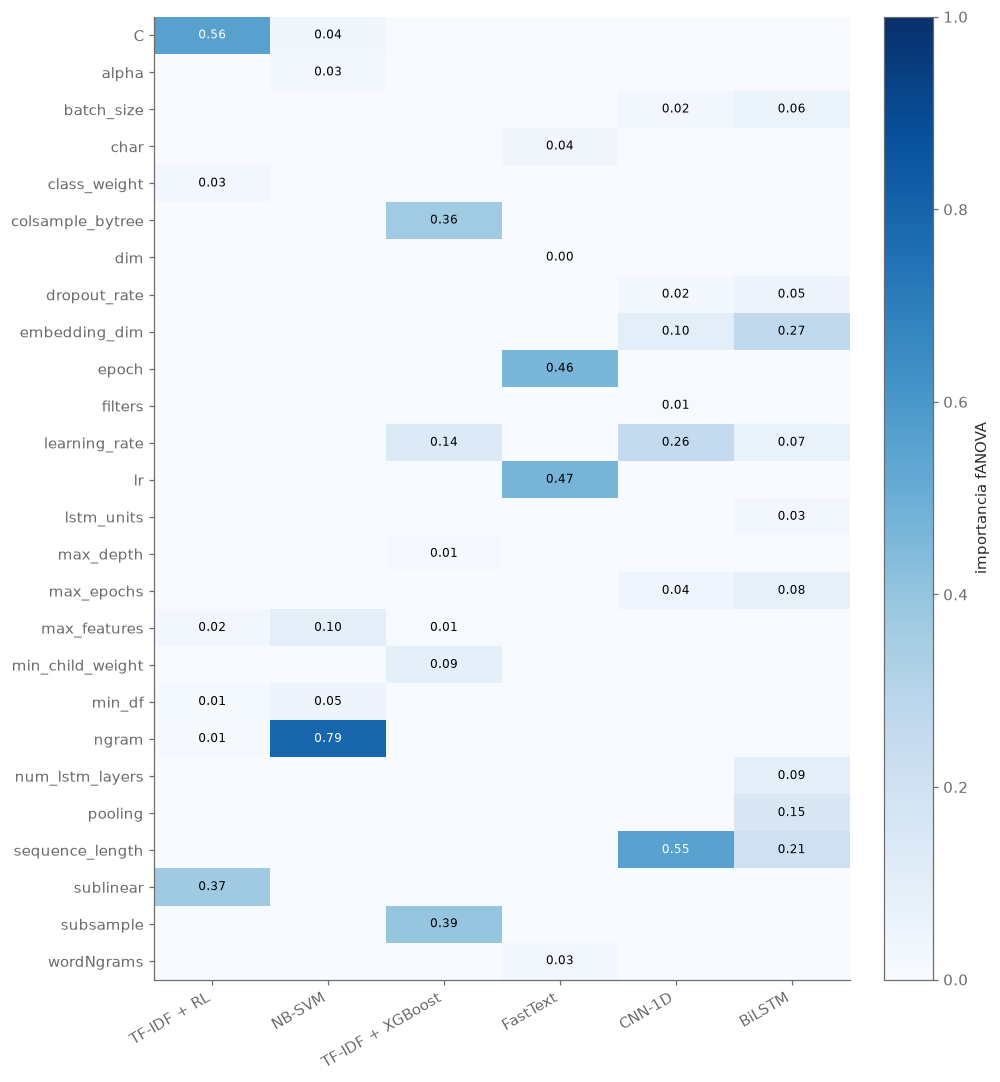

In [5]:
imp = {L[m]: pd.Series(v) for m, v in zip(H.model, H.importances) if isinstance(v, dict)}
I = pd.DataFrame(imp).fillna(0)
fig, ax = plt.subplots(figsize=(9, 0.32 * len(I) + 1.4))
im = ax.imshow(I.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_yticks(range(len(I)), I.index); ax.set_xticks(range(I.shape[1]), I.columns, rotation=30, ha="right")
for (a, b), v in np.ndenumerate(I.to_numpy()):
    if v > 0:
        ax.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.5 else "black")
ax.grid(False); fig.colorbar(im, ax=ax, label="importancia fANOVA")
plt.show()

## Dependencia parcial en la BiLSTM

Para la BiLSTM mostramos la F1 de validación de cada *trial* frente a los hiperparámetros con mayor importancia, y el efecto del tipo de *pooling*. Los *trials* podados aparecen con su última F1 intermedia.

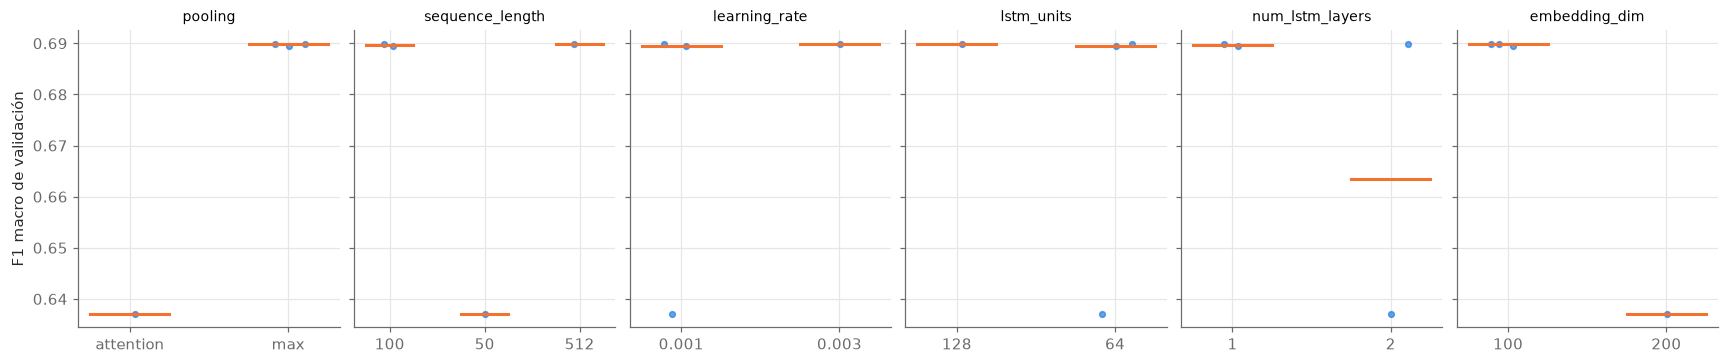

,trials,mediana,máximo
params_pooling,,,
attention,1,0.637,0.637
max,3,0.690,0.690


In [6]:
if exists("nlp/bilstm/hpo/hpo.pkl"):
    T = need("nlp/bilstm/hpo/hpo.pkl")["trials"]
    T = T[T.value.notna()]
    cols = [c for c in ["params_pooling", "params_sequence_length", "params_learning_rate", "params_lstm_units", "params_num_lstm_layers",
                        "params_embedding_dim"] if c in T.columns]
    fig, axes = plt.subplots(1, len(cols), figsize=(2.6 * len(cols), 3.2), sharey=True)
    for ax, c in zip(np.atleast_1d(axes), cols):
        lv = sorted(T[c].dropna().unique(), key=str)
        for k, v in enumerate(lv):
            y = T[T[c] == v].value
            ax.scatter(np.full(len(y), k) + np.random.default_rng(k).uniform(-0.12, 0.12, len(y)), y, s=14, color=CAT[0], alpha=0.7)
            ax.plot([k - 0.25, k + 0.25], [y.median()] * 2, color=CAT[1], lw=2)
        ax.set_xticks(range(len(lv)), [str(v) for v in lv]); ax.set_title(c.replace("params_", ""), fontsize=9)
    np.atleast_1d(axes)[0].set_ylabel("F1 macro de validación")
    plt.show()
    if "params_pooling" in T:
        display(T.groupby("params_pooling").value.agg(["count", "median", "max"]).rename(
            columns={"count": "trials", "median": "mediana", "max": "máximo"}))

La línea naranja es la mediana de los *trials* con ese valor. TPE concentra los *trials* en las regiones prometedoras, así que los valores poco explorados tienen pocos puntos y su mediana es inestable. Por eso comparamos el *pooling* aparte: la mejor configuración de la BiLSTM con cada uno de los tres tipos y el resto de hiperparámetros fijo, 3 semillas cada uno.

In [7]:
if exists("nlp/bilstm/pooling_ablation/rows.pkl"):
    Pp = pd.DataFrame(need("nlp/bilstm/pooling_ablation/rows.pkl")).drop(columns=["val"])
    g = Pp.groupby("variant").agg(F1=("f1_macro", "mean"), DE=("f1_macro", "std"), semillas=("seed", "count"),
                                  segundos=("seconds", "median")).sort_values("F1", ascending=False)
    display(g.rename(index={"last": "último estado", "max": "máximo", "attention": "atención aditiva"}))
else:
    display(Markdown("La ablación de *pooling* no terminó dentro del presupuesto."))

,F1,DE,semillas,segundos
variant,,,,
atención aditiva,0.687,0.020,3,171.451
máximo,0.686,0.005,3,189.818
último estado,0.665,0.012,3,145.985


## Sesgo optimista de la búsqueda: validación anidada

La mejor F1 de validación de la búsqueda sobreestima el rendimiento, porque elige el máximo de 30 estimaciones ruidosas (capítulo {doc}`04_fundamentos_teoricos`, punto 4). La validación anidada lo corrige: en cada uno de 5 pliegues externos, una búsqueda interna de 30 *trials* elige la configuración y el pliegue externo, que no participó, la evalúa.

In [8]:
N = S["nested"].copy()
if len(N):
    N["modelo"] = N.model.map(L)
    N["F1 externa [IC 95 %]"] = [ci(a, b, c) for a, b, c in zip(N.outer, N.outer_lo, N.outer_hi)]
    display(N[["modelo", "simple_best_val", "inner_mean", "F1 externa [IC 95 %]", "outer_sd", "bias"]].rename(
        columns={"simple_best_val": "mejor F1 de la búsqueda simple", "inner_mean": "media del mejor interno",
                 "outer_sd": "DE entre pliegues externos", "bias": "sesgo (simple − anidada)"}))
    display(Markdown(f"El sesgo optimista de la búsqueda simple va de {N.bias.min():+.3f} a {N.bias.max():+.3f} de F1 macro según el modelo. "
                     f"Lo comparamos con δ = 0.02: un sesgo de ese tamaño basta para invertir el orden de dos modelos que difieren en menos de δ."))
else:
    display(Markdown("La validación anidada no terminó dentro del presupuesto."))

,modelo,mejor F1 de la búsqueda simple,media del mejor interno,F1 externa [IC 95 %],DE entre pliegues externos,sesgo (simple − anidada)
0,TF-IDF + RL,0.659,0.643,"0.630 [0.609, 0.655]",0.03,0.029
1,NB-SVM,0.704,0.677,"0.707 [0.682, 0.726]",0.03,-0.003


El sesgo optimista de la búsqueda simple va de -0.003 a +0.029 de F1 macro según el modelo. Lo comparamos con δ = 0.02: un sesgo de ese tamaño basta para invertir el orden de dos modelos que difieren en menos de δ.

In [9]:
_have = set(N.model) if len(N) else set()
_why = {"cnn1d": "recorte 2 del pre-registro", "bilstm": "recorte 2 del pre-registro", "distilbert": "recorte 2 del pre-registro",
        "tfidf_xgb": "la búsqueda interna en CPU, estimada en 10 a 15 h por modelo, quedó al final de la cola y no se completó",
        "fasttext": "la búsqueda interna en CPU, estimada en 10 a 15 h por modelo, quedó al final de la cola y no se completó",
        "tfidf_lr": "sin completar dentro del presupuesto", "nbsvm": "sin completar dentro del presupuesto"}
_sin = [m for m in _why if m not in _have]
_txt = ("La validación anidada usa entrenamiento ∪ validación (2109 documentos) con pliegues agrupados por casi duplicados, y la búsqueda "
        "simple usa la partición fija; las dos cifras no comparten conjunto de evaluación, de modo que la diferencia mezcla el sesgo de "
        "selección con la variación entre particiones.")
if _sin:
    def _y(xs):
        return xs[0] if len(xs) == 1 else ", ".join(xs[:-1]) + " y " + xs[-1]
    _grp = {}
    for m in _sin:
        _grp.setdefault(_why[m], []).append(L[m])
    _txt += (" No hay validación anidada para " + "; ".join(f"{_y(ms)} ({w})" for w, ms in _grp.items())
             + ": sus cifras de validación de este capítulo tienen el mismo sesgo optimista, sin corregir.")
display(Markdown(_txt))

La validación anidada usa entrenamiento ∪ validación (2109 documentos) con pliegues agrupados por casi duplicados, y la búsqueda simple usa la partición fija; las dos cifras no comparten conjunto de evaluación, de modo que la diferencia mezcla el sesgo de selección con la variación entre particiones. No hay validación anidada para CNN-1D, BiLSTM y DistilBERT (recorte 2 del pre-registro); TF-IDF + XGBoost y FastText (la búsqueda interna en CPU, estimada en 10 a 15 h por modelo, quedó al final de la cola y no se completó): sus cifras de validación de este capítulo tienen el mismo sesgo optimista, sin corregir.

## Curvas de aprendizaje

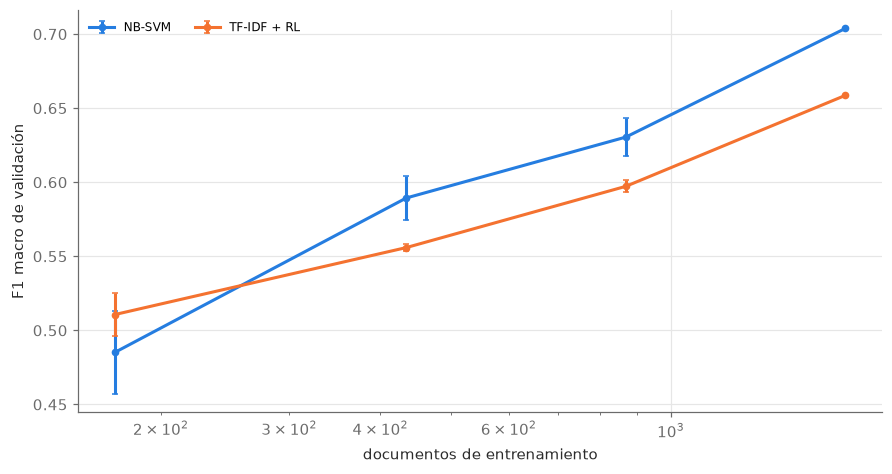

,a,b,c,F1 asintótica (1 − c)
NB-SVM,1.670,0.228,2.912e-10,1.0
TF-IDF + RL,1.058,0.147,9.660e-24,1.0


Ajustamos error(n) = a·n⁻ᵇ + c con error = 1 − F1 macro. El exponente b mide la eficiencia de datos y la asíntota c el error que no se reduce con más datos de la misma distribución. Con cuatro fracciones (tres en DistilBERT, con una semilla) y tres parámetros, el ajuste es descriptivo: la extrapolación más allá del entrenamiento completo es una indicación de tendencia. Sin curva de aprendizaje, porque su trabajo no terminó dentro del presupuesto: TF-IDF + XGBoost, FastText, CNN-1D, BiLSTM, DistilBERT.

In [10]:
lc = S["learning_curves"]
if lc:
    LC = lc["rows"]
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for k, (m, g) in enumerate(LC.groupby("model")):
        a = g.groupby("n_train").f1_macro.agg(["mean", "std"])
        ax.errorbar(a.index, a["mean"], yerr=a["std"].fillna(0), fmt="o-", ms=4, color=CAT[k % len(CAT)], label=L.get(m, m), capsize=2)
    ax.set(xscale="log", xlabel="documentos de entrenamiento", ylabel="F1 macro de validación"); ax.legend(fontsize=8, ncol=2)
    plt.show()
    fits = pd.DataFrame(lc["fits"]).T
    if len(fits) and "b" in fits:
        fits.index = fits.index.map(lambda m: L.get(m, m))
        fits["F1 asintótica (1 − c)"] = 1 - fits.c
        display(fits[["a", "b", "c", "F1 asintótica (1 − c)"]])
_lc_have = set(lc["rows"].model) if lc else set()
_lc_miss = [L[m] for m in ("tfidf_lr", "nbsvm", "tfidf_xgb", "fasttext", "cnn1d", "bilstm", "distilbert") if m not in _lc_have]
display(Markdown(
    "Ajustamos error(n) = a·n⁻ᵇ + c con error = 1 − F1 macro. El exponente b mide la eficiencia de datos y la asíntota c el error "
    "que no se reduce con más datos de la misma distribución. Con cuatro fracciones (tres en DistilBERT, con una semilla) y tres "
    "parámetros, el ajuste es descriptivo: la extrapolación más allá del entrenamiento completo es una indicación de tendencia."
    + (f" Sin curva de aprendizaje, porque su trabajo no terminó dentro del presupuesto: {', '.join(_lc_miss)}." if _lc_miss else "")))